# Comparing Glutamate distribution with alpha MEG

Load MEG alpha distribution and Glutamate receptor distribution from Dubois 2015. MEG alpha distribution is a surface map in fsLR space. Glutamate receptor distribution is a volumetric map in MNI 152 space.

In [36]:
from neuromaps import datasets

megalpha = datasets.fetch_annotation(desc='megalpha', return_single=True)
dubois = datasets.fetch_annotation(source='dubois2015', return_single=True)
print(megalpha) # fsLR 4k
print(dubois) # MNI152 1mm


[References] Please cite the following papers if you are using this data:

  For {'source': 'hcps1200', 'desc': 'megalpha', 'space': 'fsLR', 'den': '4k'}:
  [primary]:
    David C Van Essen, Stephen M Smith, Deanna M Barch, Timothy EJ Behrens, Essa Yacoub, Kamil Ugurbil, Wu-Minn HCP Consortium, and others. The wu-minn human connectome project: an overview. Neuroimage, 80:62–79, 2013.
    Golia Shafiei, Sylvain Baillet, and Bratislav Misic. Human electromagnetic and haemodynamic networks systematically converge in unimodal cortex and diverge in transmodal cortex. PLoS biology, 20(8):e3001735, 2022.
  [secondary]:
    

[References] Please cite the following papers if you are using this data:

  For {'source': 'dubois2015', 'desc': 'abp688', 'space': 'MNI152', 'res': '1mm'}:
  [primary]:
    Jonathan M DuBois, Olivier G Rousset, Jared Rowley, Manuel Porras-Betancourt, Andrew J Reader, Aurelie Labbe, Gassan Massarweh, Jean-Paul Soucy, Pedro Rosa-Neto, and Eliane Kobayashi. Characterizati

In order to compare both maps we have to transform them to the same space. In this case we will transform them to fsaverage space with 10k density. Note that we cannot transform a surface map to volumetric space because it is an ill-posed problem. To run this snippet of code one must have the connectome workbench installed and running (check the document how_to_run.md)

In [17]:
from neuromaps import resampling

# Resample datasets to surface so we can compare them
dubois, megalpha = resampling.resample_images(src=dubois, trg=megalpha,
                                            src_space='MNI152',
                                            trg_space='fsLR',
                                            resampling='transform_to_alt',
                                            alt_spec=('fsaverage', '10k'))
print(dubois, megalpha)

(<nibabel.gifti.gifti.GiftiImage object at 0x000002D12C41FD60>, <nibabel.gifti.gifti.GiftiImage object at 0x000002D12C41F790>) (<nibabel.gifti.gifti.GiftiImage object at 0x000002D11FD85250>, <nibabel.gifti.gifti.GiftiImage object at 0x000002D11FD91580>)


Resample image using low level functions

Now we want to see how the two distributions look like to geta vibe of the data. We will plot them on the fsaverage brain.

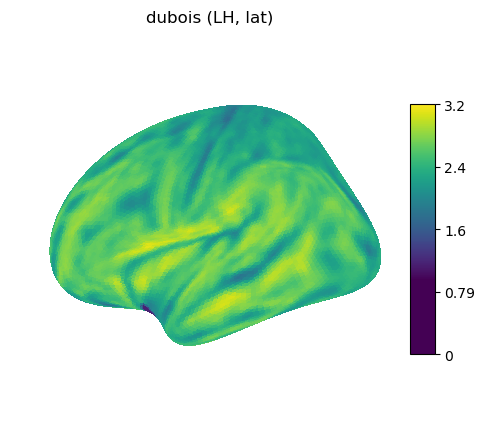

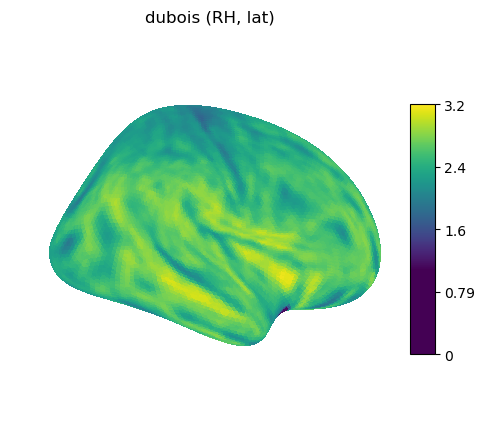

In [34]:
from neuromaps.datasets import fetch_fsaverage
from nilearn import plotting

# fetch fsaverage meshes (same density you resampled to)
fs = fetch_fsaverage(density="10k")

# unpack hemispheres (each is a nibabel GiftiImage)
dubois_lh, dubois_rh = dubois

# extract vertex-wise arrays
dubois_lh_data = dubois_lh.darrays[0].data
dubois_rh_data = dubois_rh.darrays[0].data

# plot dubois (inflated surface)
plotting.plot_surf_stat_map(fs["inflated"].L, dubois_lh_data, hemi="left",  view="lateral",
                            cmap="viridis", colorbar=True, title="dubois (LH, lat)")
plotting.plot_surf_stat_map(fs["inflated"].R, dubois_rh_data, hemi="right", view="lateral",
                            cmap="viridis", colorbar=True, title="dubois (RH, lat)")
plotting.show()


We can also plot the resampled maps with the neuromaps plotting function

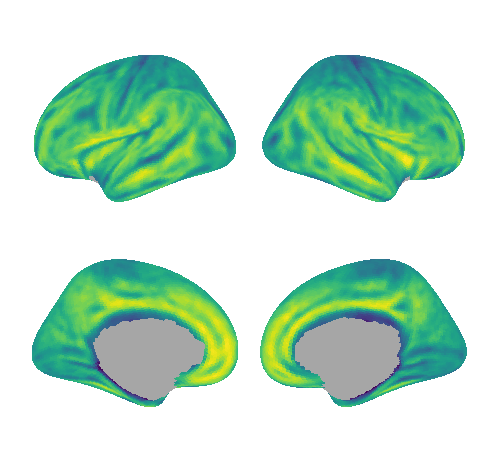

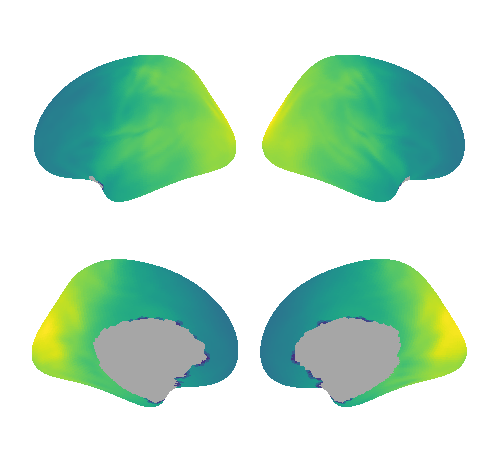

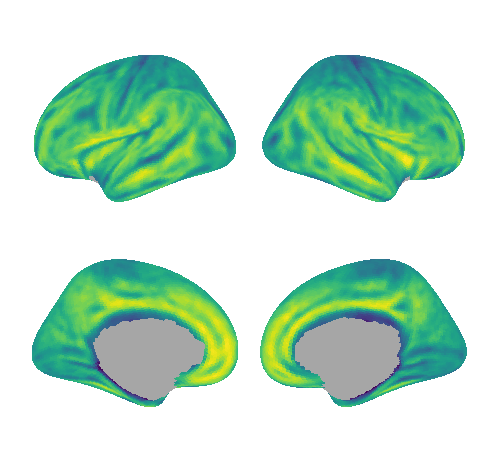

In [19]:
from neuromaps.plotting import plot_surf_template

plot_surf_template(megalpha,template='fsaverage',density='10k',mask_medial=True)
plot_surf_template(dubois,template='fsaverage',density='10k',mask_medial=True)


Once the images are resampled we can easily correlate them:



In [20]:
from neuromaps import stats
corr = stats.compare_images(dubois, megalpha)
print(f'Correlation: r = {corr:.02f}')

Correlation: r = -0.20


What if we want to assess the statistical significance of this correlation?
In this case, we can use a null model from the :mod:`neuromaps.nulls` module.

Here, we'll employ the null model proposed in Alexander-Bloch et al., 2018,
*NeuroImage*. We provide one of the maps we're comparing, the space + density
of the map, and the number of permutations we want to generate. The returned
array will have two dimensions, where each row corresponds to a vertex and
each column to a unique permutation.

(Note that we need to pass the loaded data from the provided map to the null
function so we use the :func:`neuromaps.images.load_data` utility.)



In [21]:
from neuromaps import images, nulls
dubois_data = images.load_data(dubois)
rotated = nulls.alexander_bloch(dubois_data, atlas='fsaverage', density='10k',
                                n_perm=100, seed=1234)
print(rotated.shape)

(20484, 100)


We can supply the generated null array to the
:func:`neuromaps.stats.compare_images` function and it will be used to
generate a non-parameteric p-value. The function assumes that the array
provided to the `nulls` parameter corresponds to the *first* dataset passed
to the function (i.e., `nsynth`).

Note that the correlation remains identical to that above but the p-value is
now returned as well:



In [ ]:
corr, pval = stats.compare_images(dubois, megalpha, nulls=rotated)
print(f'Correlation: r = {corr:.02f}, p = {pval:.04f}')

Check available MEG annotations and receptors

In [ ]:
meg_annotations = datasets.available_annotations(tags='MEG')
print(meg_annotations)
receptors = datasets.available_annotations(tags='receptors')
print(receptors)

There are a number of different null functions that can be used to generate
null maps; they have (nearly) identical function signatures, so refer to the
`API reference <ref_nulls>` for more information.




[References] Please cite the following papers if you are using this data:

  For {'source': 'dubois2015', 'desc': 'abp688', 'space': 'MNI152', 'res': '1mm'}:
  [primary]:
    Jonathan M DuBois, Olivier G Rousset, Jared Rowley, Manuel Porras-Betancourt, Andrew J Reader, Aurelie Labbe, Gassan Massarweh, Jean-Paul Soucy, Pedro Rosa-Neto, and Eliane Kobayashi. Characterization of age/sex and the regional distribution of mglur5 availability in the healthy human brain measured by high-resolution [11 c] abp688 pet. European journal of nuclear medicine and molecular imaging, 43(1):152–162, 2016.
    Justine Y Hansen, Golia Shafiei, Ross D Markello, Kelly Smart, Sylvia ML Cox, Martin Nørgaard, Vincent Beliveau, Yanjun Wu, Jean-Dominique Gallezot, Étienne Aumont, and others. Mapping neurotransmitter systems to the structural and functional organization of the human neocortex. Nature neuroscience, 25(11):1569–1581, 2022.
  [secondary]:
    


C:\Users\Cristina\miniconda3\envs\pysurfer_env\lib\site-packages\numpy\core\fromnumeric.py:771: UserWarning: Warning: 'partition' will ignore the 'mask' of the MaskedArray.
  a.partition(kth, axis=axis, kind=kind, order=order)



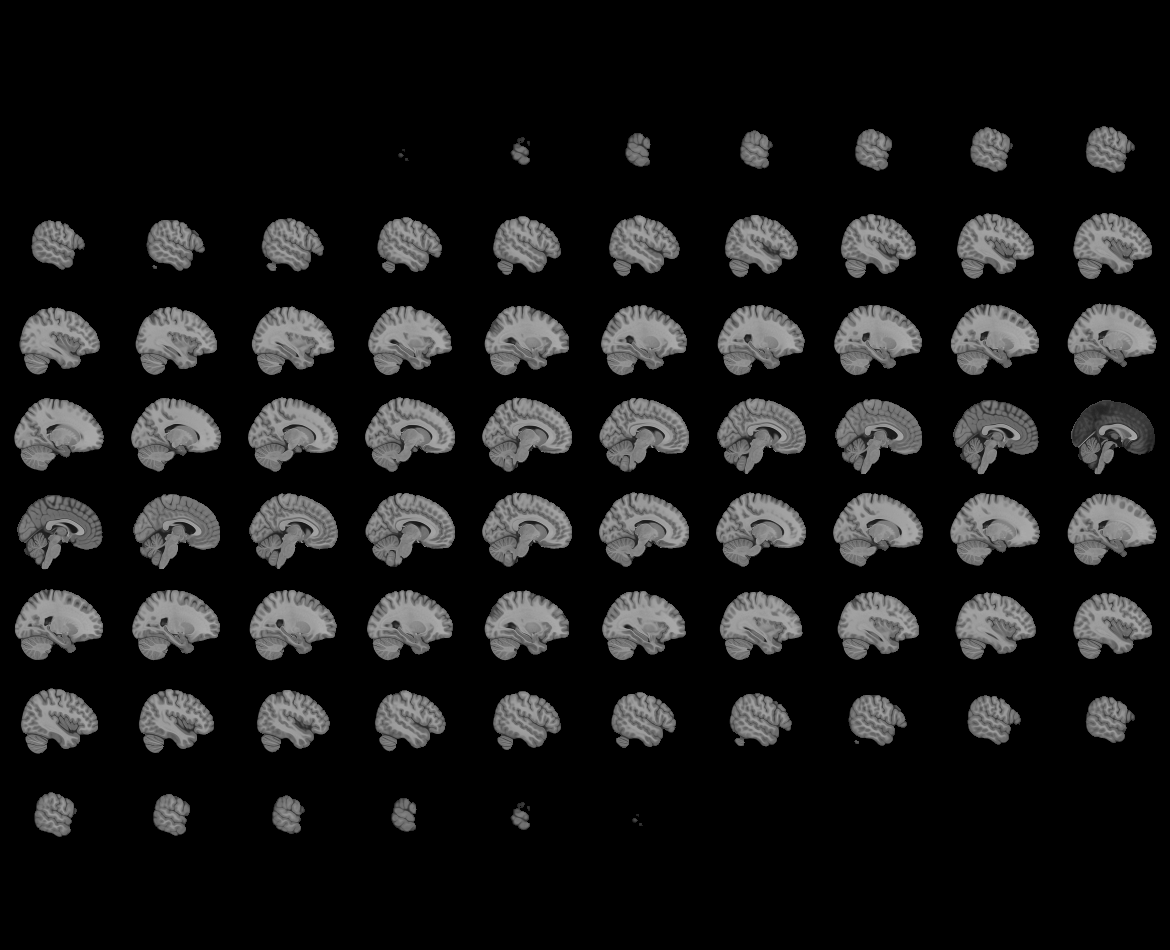
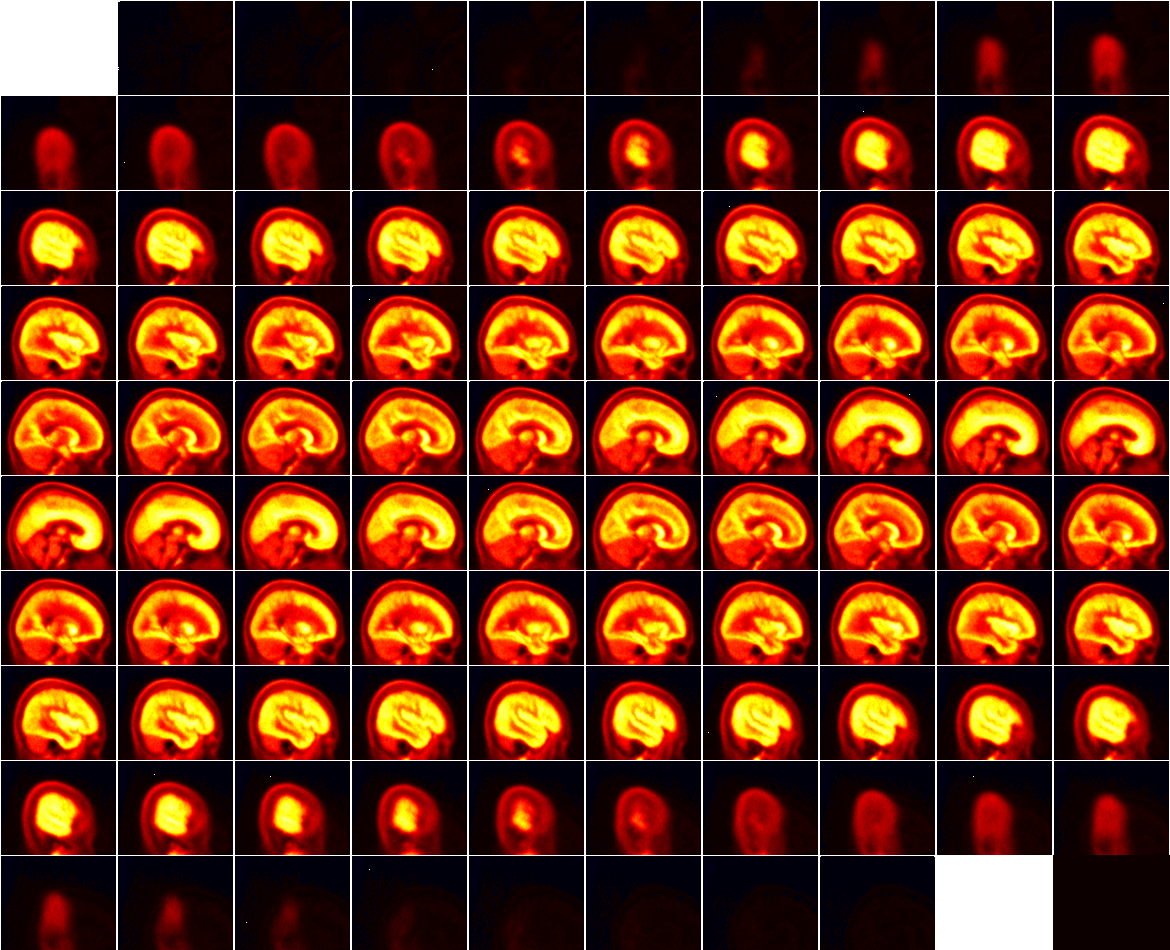

In [37]:
from neuromaps import datasets
from nilearn import plotting

dubois = datasets.fetch_annotation(source="dubois2015", return_single=True)  # path to .nii.gz


In [47]:
# Import the actual dubois data
import nibabel as nib
import numpy as np
img = nib.load(dubois)     # load NIfTI
data = img.get_fdata()     # numpy array
print(data.shape)

vmin = np.nanmin(data)
vmax = np.nanmax(data)

vmin, vmax

(193, 229, 193)


(-0.047006189823150635, 3.408548593521118)

C:\Users\Cristina\AppData\Local\Temp\ipykernel_11464\3710565696.py:1: UserWarning: you have specified symmetric_cmap=False but the map contains negative values; setting symmetric_cmap to True
  plotting.view_img(dubois, symmetric_cmap=False)  # interactive in Jupyter
C:\Users\Cristina\miniconda3\envs\pysurfer_env\lib\site-packages\numpy\core\fromnumeric.py:771: UserWarning: Warning: 'partition' will ignore the 'mask' of the MaskedArray.
  a.partition(kth, axis=axis, kind=kind, order=order)



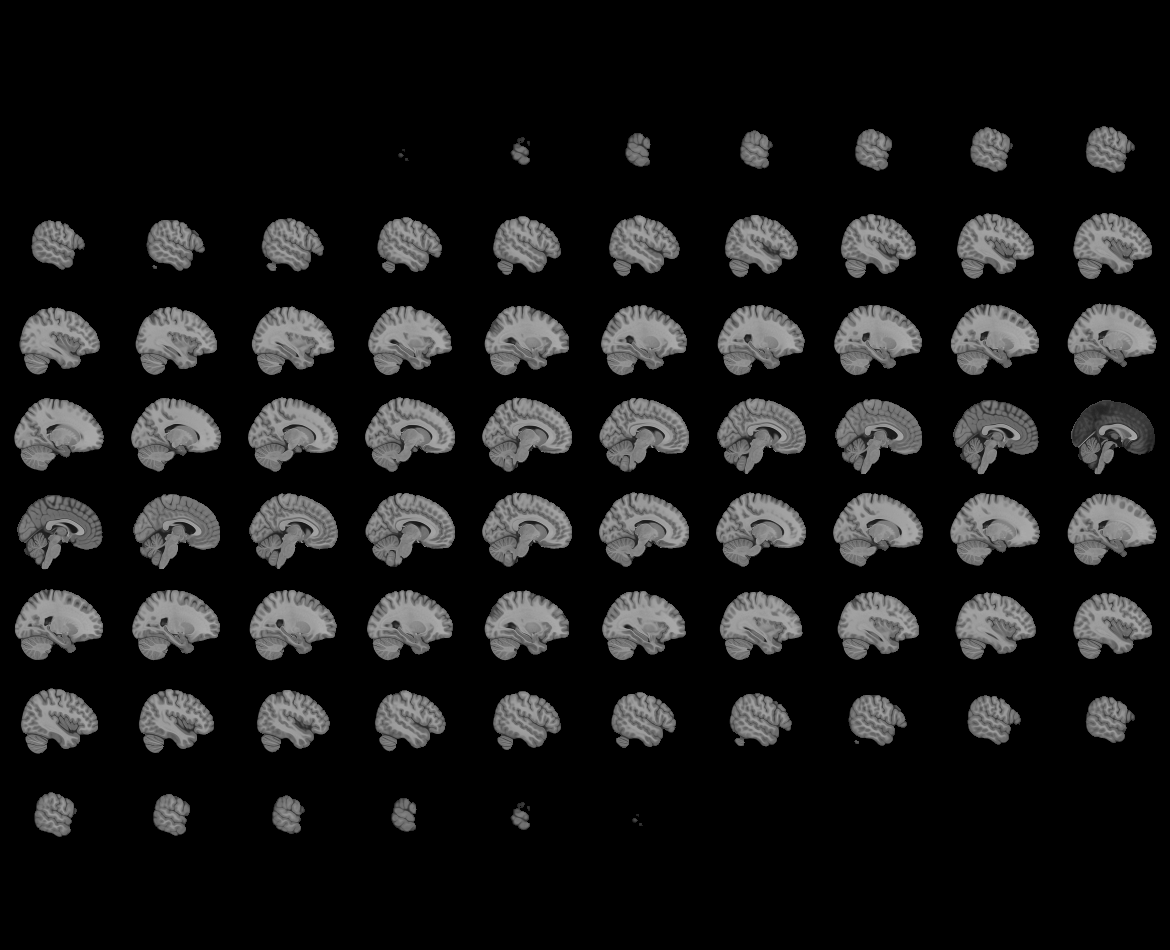
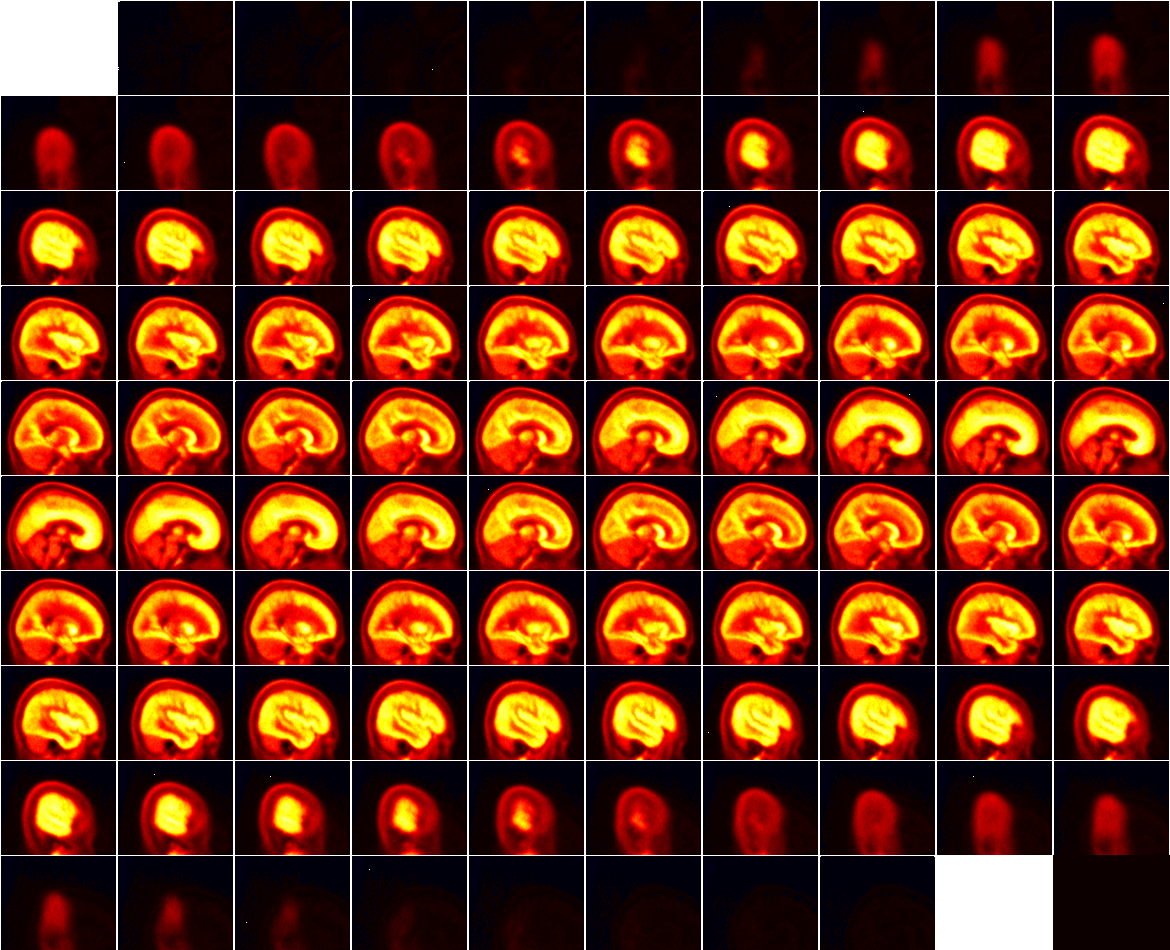

In [43]:
plotting.view_img(dubois, symmetric_cmap=False)  # interactive in Jupyter

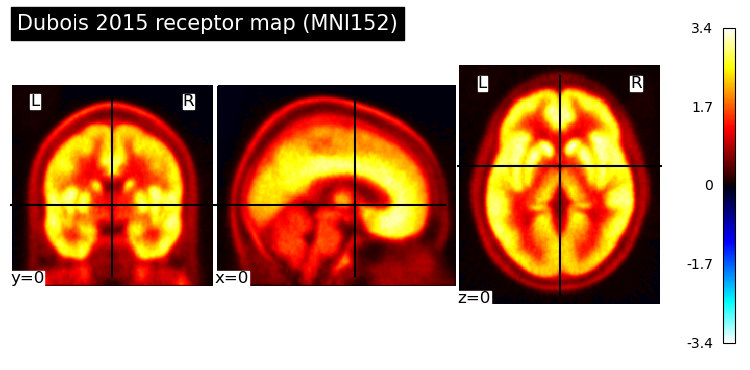

In [38]:
plotting.plot_stat_map(
    dubois,
    display_mode="ortho",  # 'x', 'y', 'z', 'ortho'
    cut_coords=(0, 0, 0),
    colorbar=True,
    title="Dubois 2015 receptor map (MNI152)"
)
plotting.show()

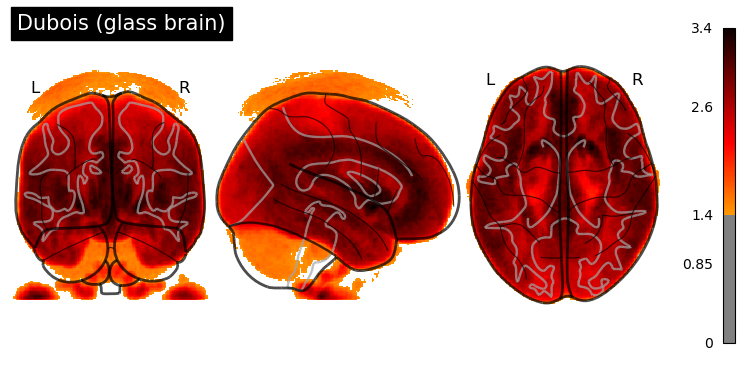

In [39]:
plotting.plot_glass_brain(dubois, colorbar=True, title="Dubois (glass brain)")
plotting.show()


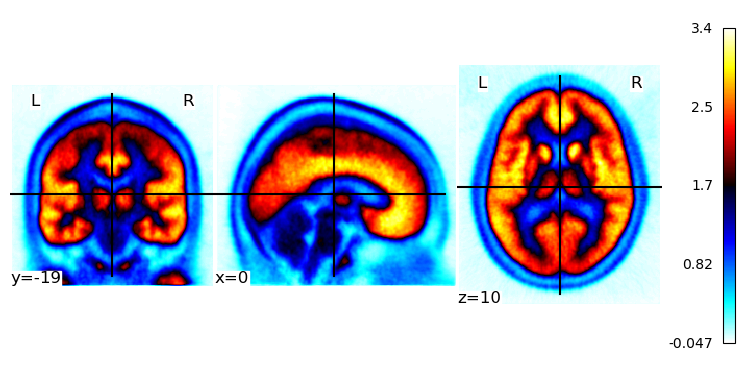

In [40]:
plotting.plot_stat_map(dubois, vmax="auto", symmetric_cbar=False, colorbar=True)
plotting.show()
